# Convert and Optimize AdaBLDM (ControlNet + Stable-Diffusion UNet) defect generation with OpenVINO™

[AdaBLDM](https://github.com/GrandpaXun242/AdaBLDM) ([paper](https://arxiv.org/abs/2402.19330)) is a blended latent
diffusion model that generates **defects on industrial product images**: a ControlNet branch conditions a
Stable-Diffusion v1.5 UNet on a "triple map" (object mask + defect mask) plus a text prompt, so defects appear where
the mask says they belong. Synthetic defect images are used to train and balance downstream inspection models when
real defective samples are rare.

Like every ControlNet pipeline, the network is the **denoiser** — a ControlNet branch fused with a UNet — while the
DDIM sampler and the triple-map assembly run on the host. OpenVINO replaces exactly the denoiser: this notebook
converts it to FP32/FP16 IR, quantizes it to INT8 with NNCF and benchmarks every precision.

**A note on weights.** The upstream repository publishes no trained checkpoint (`test.py` points at a local training
output), so this notebook follows the project's documented **pretrain stage**: it builds the AdaBLDM architecture and
initializes it from the public Stable-Diffusion v1.5 weights, exactly like the upstream `tool_add_control.py` script.
The compute graph — and therefore the latency, throughput and model size OpenVINO optimizes — is identical to a
fine-tuned AdaBLDM; only the weight values differ.

**Table of contents**

1. [Prerequisites](#Prerequisites:)
2. [Get the AdaBLDM repository and base checkpoint](#Get-the-AdaBLDM-repository-and-base-checkpoint:)
3. [Build the PyTorch FP32 denoiser](#Build-the-PyTorch-FP32-denoiser:)
4. [Convert the model to OpenVINO IR](#Convert-the-model-to-OpenVINO-IR:)
5. [Select inference device](#Select-inference-device:)
6. [Accuracy of OpenVINO FP32 and FP16](#Accuracy-of-OpenVINO-FP32-and-FP16:)
7. [Generate a sample image](#Generate-a-sample-image:)
8. [Optimize model using NNCF Post-training Quantization API](#Optimize-model-using-NNCF-Post-training-Quantization-API:)
9. [Compare performance of the models with benchmark_app](#Compare-performance-of-the-models-with-benchmark_app:)
10. [Accuracy and performance: OpenVINO vs PyTorch](#Accuracy-and-performance:-OpenVINO-vs-PyTorch:)

## Prerequisites
[back to top ⬆️](#Table-of-contents:)

In [1]:
%pip install -q torch torchvision --extra-index-url https://download.pytorch.org/whl/cpu
%pip install -q "openvino>=2025.1" "nncf>=2.12" omegaconf einops pytorch_lightning transformers huggingface_hub ipywidgets matplotlib
import subprocess
import sys, json, time, shutil
from pathlib import Path
import numpy as np, torch
import openvino as ov
import nncf
import adabldm_nb_utils as U
from IPython.display import Image, display, Markdown

core = ov.Core()
print("OpenVINO", ov.__version__, "| NNCF", nncf.__version__, "| torch", torch.__version__)
print("devices:", {d: core.get_property(d, "FULL_DEVICE_NAME") for d in core.available_devices})
OUT = Path("results")                                       # relative to this notebook
(OUT / "images").mkdir(parents=True, exist_ok=True)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/ubuntu/ai-dev/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/ubuntu/ai-dev/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


OpenVINO 2026.4.1-22982-e213a147257-releases/2026/4 | NNCF 3.4.0 | torch 2.14.0.dev20260725+xpu
devices: {'CPU': 'Genuine Intel(R) 0000', 'GPU': 'Intel(R) Arc(TM) A770 Graphics (dGPU)'}


## Get the AdaBLDM repository and base checkpoint
[back to top ⬆️](#Table-of-contents:)

The notebook clones the unmodified AdaBLDM repository (the `cldm` / `ldm` packages provide the model definitions) and
downloads the public Stable-Diffusion v1.5 checkpoint used for the pretrain initialization. Both are reused when they
already exist; set `ADABLDM_BASE_CKPT` to point at a local copy of `v1-5-pruned-emaonly.ckpt`.

In [2]:
U.ensure_repo()
U.setup_compat()
base_ckpt = U.download_base()
print("base checkpoint:", base_ckpt, f"({base_ckpt.stat().st_size / 2**30:.1f} GiB)")

base checkpoint: /home/ubuntu/models/v1-5-pruned-emaonly.ckpt (4.0 GiB)


## Build the PyTorch FP32 denoiser
[back to top ⬆️](#Table-of-contents:)

`build_denoiser` constructs the two networks from `models/cldm_v15.yaml` — a `ControlledUnetModel` and a `ControlNet` —
copies the Stable-Diffusion v1.5 weights into the UNet and into the ControlNet's shared trunk, and leaves the
ControlNet's zero convolutions newly initialized (the upstream pretrain stage). The two are then fused into a single
module with one forward pass:

```python
class Denoiser(torch.nn.Module):
    def forward(self, x, hint, t, context):
        control = list(self.cnet(x, hint, t, context))
        return self.unet(x, t, context, control=control)
```

so the whole ControlNet + UNet graph converts as one OpenVINO model. The inputs are the noisy latent
`x [1,4,32,32]`, the triple-map `hint [1,3,256,256]`, the timestep `t [1]` and the CLIP text embedding
`context [1,77,768]`.

In [3]:
den = U.build_denoiser()
context = U.encode_prompt("a photo of a metal surface with a scratch")
x0, hint, tstep, context = U.make_inputs(context)
print("inputs:", [tuple(a.shape) for a in (x0, hint, tstep, context)])

No module 'xformers'. Proceeding without it.


SD v1.5 init: UNet 859.5M, ControlNet 361.3M (298 ControlNet tensors copied from SD v1.5, zero convs newly initialized)


Failed to load /home/ubuntu/ai-dev/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /home/ubuntu/ai-dev/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


Failed to load /home/ubuntu/ai-dev/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /home/ubuntu/ai-dev/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so


W1120 17:42:58.397000 937976 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1120 17:42:58.430000 937976 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}

inputs: [(1, 4, 32, 32), (1, 3, 256, 256), (1,), (1, 77, 768)]


## Convert the model to OpenVINO IR
[back to top ⬆️](#Convert-the-model-to-OpenVINO-IR:)

### FP32 IR and FP16 IR

`torch.export` traces the fused denoiser with dynamic dimensions; `static_shapes` pins every input to the fixed
batch-1 shapes used by the sampler, which is also what `benchmark_app` requires.

In [4]:
IR_DIR = Path("ov_models")                                       # relative to this notebook
IR_DIR.mkdir(exist_ok=True)

t0 = time.time()
model = U.static_shapes(ov.convert_model(den, example_input=(x0, hint, tstep, context)))
print(f"converted in {time.time() - t0:.1f}s | inputs:", {i.get_any_name(): list(i.get_shape()) for i in model.inputs})

fp32_path = IR_DIR / "adabldm_denoiser_fp32.xml"
ov.save_model(model, fp32_path, compress_to_fp16=False)
fp16_path = IR_DIR / "adabldm_denoiser_fp16.xml"
ov.save_model(model, fp16_path, compress_to_fp16=True)
for p in (fp32_path, fp16_path):
    print(p.name, f"{p.with_suffix('.bin').stat().st_size / 2**20:.0f} MiB")

/home/ubuntu/ai-dev/lib/python3.12/site-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ubuntu/ai-dev/lib/python3.12/site-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/home/ubuntu/openvino_notebooks/notebooks/AdaBLDM/ldm/modules/diffusionmodules/openaimodel.py:172: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert x.shape[1] == self.channels


/home/ubuntu/openvino_notebooks/notebooks/AdaBLDM/ldm/modules/diffusionmodules/openaimodel.py:114: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert x.shape[1] == self.channels


converted in 20.0s | inputs: {'207': [1, 4, 32, 32], 'hint': [1, 3, 256, 256], '110': [1], 'context': [1, 77, 768]}


adabldm_denoiser_fp32.xml 3291 MiB
adabldm_denoiser_fp16.xml 1646 MiB


## Select inference device
[back to top ⬆️](#Table-of-contents:)

In [5]:
import ipywidgets as widgets
device = widgets.Dropdown(options=core.available_devices + ["AUTO"], value="GPU" if "GPU" in core.available_devices else "CPU",
                          description="Device:")
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'AUTO'), value='GPU')

## Accuracy of OpenVINO FP32 and FP16
[back to top ⬆️](#Table-of-contents:)

The denoiser output is a noise prediction, so accuracy is measured as the cosine similarity against the PyTorch FP32
reference on the same inputs — the standard parity check for diffusion UNets. On GPU, FP32 IR is executed with an
`f32` inference-precision hint so the comparison is fair.

In [6]:
FP32_PROPS = {"INFERENCE_PRECISION_HINT": "f32"} if device.value.startswith("GPU") else {}
ins = [a.numpy() for a in (x0, hint, tstep, context)]

torch_run = U.torch_runner(den)
ref = torch_run(x0, hint, tstep, context)
_, pt_ms = U.timeit(torch_run, x0, hint, tstep, context, n=3, warmup=1)

acc, perf = {"PT FP32": {"cosine": 1.0, "sync_ms": round(pt_ms, 1)}}, {}
for tag, path in (("OV FP32", fp32_path), ("OV FP16", fp16_path)):
    run = U.ov_runner(core, path, device.value, **FP32_PROPS)
    y, ms = U.timeit(run, *ins)
    acc[tag] = {"cosine": round(U.cosine(y, ref), 6), "sync_ms": round(ms, 1)}
    print(f"{tag} on {device.value} (precision hint {run.exec_precision}): cosine {acc[tag]['cosine']:.6f} | {ms:.1f} ms")
print(f"PT FP32 on CPU: {pt_ms:.1f} ms")

OV FP32 on GPU (precision hint <Type: 'float32'>): cosine 1.000000 | 85.0 ms


OV FP16 on GPU (precision hint <Type: 'float32'>): cosine 1.000000 | 87.7 ms
PT FP32 on CPU: 497.0 ms


## Generate a sample image
[back to top ⬆️](#Generate-a-sample-image:)

The OpenVINO denoiser now drives a 20-step DDIM sampler (eta = 0) exactly as the upstream `sample_ccdm` does; the
sampler and the Stable-Diffusion VAE decode stay on the host. With pretrain weights the picture is a plausible but
untrained diffusion sample — the point is that the full generation loop runs on the converted model.

making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels


20-step DDIM + VAE decode in 2.1s on GPU


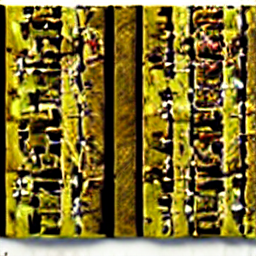

In [7]:
import matplotlib.pyplot as plt

SCALE = 0.18215
from omegaconf import OmegaConf
_cfg = OmegaConf.load(str(U.REPO / U.MODEL_YAML))
_betas = np.linspace(_cfg.model.params.linear_start ** 0.5, _cfg.model.params.linear_end ** 0.5, 1000) ** 2
alpha_bar = np.cumprod(1 - _betas)

def ddim_generate(run, ctx_np, steps=20, seed=7):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(1, 4, *U.LATENT_HW, generator=g).numpy()
    hint_np = np.zeros((1, 3, *U.IMAGE_HW), np.float32)      # empty triple map
    sched = np.linspace(999, 0, steps).round().astype(int)   # descending timesteps
    for i, step in enumerate(sched):
        eps = run(x, hint_np, np.full((1,), float(step), np.float32), ctx_np)
        a0 = alpha_bar[step]
        a1 = alpha_bar[sched[i + 1]] if i + 1 < len(sched) else 1.0
        x = (np.sqrt(a1) * (x - np.sqrt(1 - a0) * eps) / np.sqrt(a0) + np.sqrt(1 - a1) * eps).astype(np.float32)
    return x

vae = U.build_vae()

def decode_to_image(latent_np):
    with torch.no_grad():
        img = vae.decode(torch.from_numpy(latent_np.astype(np.float32)) / SCALE)
    return (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).numpy()[0]

fp32_run = U.ov_runner(core, fp32_path, device.value, **FP32_PROPS)
t0 = time.time()
img_fp32 = decode_to_image(ddim_generate(fp32_run, context.numpy()))
print(f"20-step DDIM + VAE decode in {time.time() - t0:.1f}s on {device.value}")
plt.imsave(OUT / "images/generated_fp32.png", img_fp32)
display(Image(filename=str(OUT / "images/generated_fp32.png")))

## Optimize model using NNCF Post-training Quantization API
[back to top ⬆️](#Table-of-contents:)

Please select below whether you would like to run quantization to improve model inference speed.

In [8]:
IR_DIR.joinpath("INT8").mkdir(parents=True, exist_ok=True)
int8_path = IR_DIR / "INT8" / "adabldm_denoiser_int8.xml"

to_quantize = widgets.Checkbox(value=True, description="Quantization")
to_quantize

Checkbox(value=True, description='Quantization')

Let's load `skip magic` extension to skip quantization if `to_quantize` is not selected

In [9]:
if not Path("skip_kernel_extension.py").exists():
    import requests
    r = requests.get(
        url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/skip_kernel_extension.py",
    )
    open("skip_kernel_extension.py", "w").write(r.text)

%load_ext skip_kernel_extension

Prepare the calibration dataset for quantization: five denoiser input tuples (random latents and timesteps around
the middle of the schedule, the same text context used above). For a production deployment, calibrate on latents
collected from real triple maps instead.

In [10]:
%%skip not $to_quantize.value

N_CALIB = 5
cal_inputs = [U.make_inputs(context, seed=s) for s in range(N_CALIB)]
calib = nncf.Dataset(cal_inputs, lambda tup: [a.numpy() for a in tup])
print(f"{N_CALIB} calibration samples")

5 calibration samples


The `nncf.quantize` function provides an interface for model quantization. It requires an instance of the OpenVINO
model and the calibration dataset. The MIXED preset keeps the UNet's attention `Multiply`/`Add` chain in float, which
protects diffusion-model output quality.

In [11]:
%%skip not $to_quantize.value

t0 = time.time()
quantized_model = nncf.quantize(
    core.read_model(fp32_path),
    calib,
    preset=nncf.QuantizationPreset.MIXED,
    subset_size=N_CALIB,
    fast_bias_correction=True,
    ignored_scope=nncf.IgnoredScope(types=["Multiply", "Add"]),
)
print(f"quantized in {time.time() - t0:.0f}s | "
      f"{sum(o.get_type_name() == 'FakeQuantize' for o in quantized_model.get_ordered_ops())} FakeQuantize ops")
ov.save_model(quantized_model, int8_path, compress_to_fp16=False)

INFO:nncf:754 ignored nodes were found by types in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 41 __module.unet/aten::mul/Multiply_1


INFO:nncf:Not adding activation input quantizer for operation: 316 __module.unet.input_blocks.1.0/aten::add/Add


INFO:nncf:Not adding activation input quantizer for operation: 75 __module.cnet/aten::add_/Add


INFO:nncf:Not adding activation input quantizer for operation: 469 __module.cnet.input_blocks.1.0/aten::add/Add


INFO:nncf:Not adding activation input quantizer for operation: 117 __module.cnet.input_blocks.1.0/aten::add/Add_1


... (234 outputs left out)

INFO:nncf:Not adding activation input quantizer for operation: 491 __module.unet.output_blocks.11.1/aten::add/Add


Output()

Output()

quantized in 103s | 454 FakeQuantize ops


### Validate quantized model inference
[back to top ⬆️](#Table-of-contents:)

OV INT8 on GPU: cosine 0.997992 | 37.4 ms


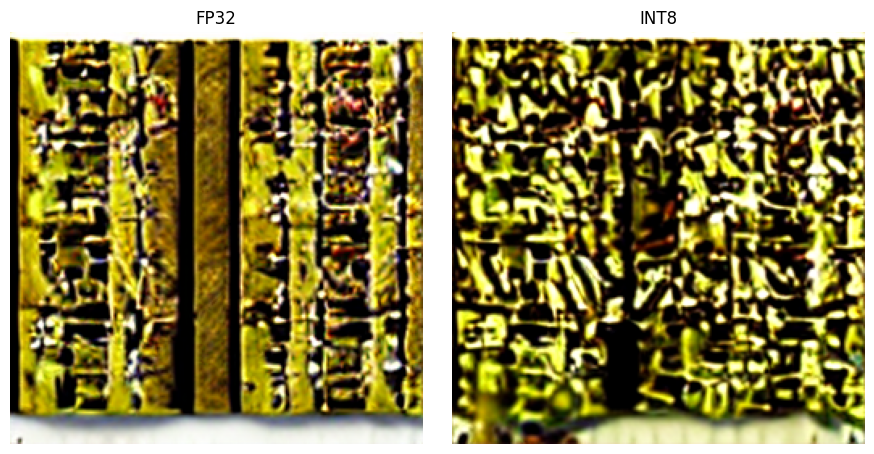

In [12]:
%%skip not $to_quantize.value

int8_run = U.ov_runner(core, int8_path, device.value, **FP32_PROPS)
y8, ms8 = U.timeit(int8_run, *ins)
acc["OV INT8"] = {"cosine": round(U.cosine(y8, ref), 6), "sync_ms": round(ms8, 1)}
print(f"OV INT8 on {device.value}: cosine {acc['OV INT8']['cosine']:.6f} | {ms8:.1f} ms")

img_int8 = decode_to_image(ddim_generate(int8_run, context.numpy()))
plt.imsave(OUT / "images/generated_int8.png", img_int8)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (title, im) in zip(axs, (("FP32", img_fp32), ("INT8", img_int8))):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "images/fp32_vs_int8.png", dpi=110); plt.show()

## Compare performance of the models with benchmark_app
[back to top ⬆️](#Table-of-contents:)

`benchmark_app` reports queue-inclusive async latency and throughput; the model already carries static input shapes, so
no `-shape` flag is needed.

In [13]:
device

Dropdown(description='Device:', index=1, options=('CPU', 'GPU', 'AUTO'), value='GPU')

In [14]:
BENCH = OUT / "benchmark"; BENCH.mkdir(parents=True, exist_ok=True)
BENCH_TIME = 15
# benchmark_app ships with the openvino pip package; use the one next to this kernel's python if it is not on PATH
benchmark_app = shutil.which("benchmark_app") or str(Path(sys.executable).parent / "benchmark_app")

def bench(model_path, tag, extra=()):
    log = BENCH / f"{tag}.log"
    cmd = [benchmark_app, "-m", str(model_path), "-d", device.value, "-t", str(BENCH_TIME), "-api", "async", *extra]
    with open(log, "w") as fh:
        subprocess.run(cmd, stdout=fh, stderr=subprocess.STDOUT, check=True)
    perf[tag] = U.parse_benchmark_log(log)
    print(tag, perf[tag])

FP32_FLAGS = ["-infer_precision", "f32"] if device.value.startswith("GPU") else []
bench(fp32_path, "OV_FP32", FP32_FLAGS)
bench(fp16_path, "OV_FP16")

OV_FP32 {'avg_ms': 300.78, 'fps': 13.19, 'nireq': None}


OV_FP16 {'avg_ms': 100.63, 'fps': 39.56, 'nireq': None}


In [15]:
%%skip not $to_quantize.value

bench(int8_path, "OV_INT8", FP32_FLAGS if device.value.startswith("GPU") else [])

OV_INT8 {'avg_ms': 101.04, 'fps': 39.39, 'nireq': None}


## Accuracy and performance: OpenVINO vs PyTorch
[back to top ⬆️](#Table-of-contents:)

All numbers were measured on the same machine with the same settings:
* **accuracy**: cosine similarity of the denoiser output against the PyTorch FP32 reference on identical inputs;
* **performance**: single-stream latency measured in this notebook, plus `benchmark_app` async latency and throughput.

In [16]:
names = {"PT FP32": "PyTorch FP32 (CPU)", "OV FP32": "OpenVINO FP32", "OV FP16": "OpenVINO FP16",
         "OV INT8": "OpenVINO INT8 (NNCF)"}
bench_key = {"OV FP32": "OV_FP32", "OV FP16": "OV_FP16", "OV INT8": "OV_INT8"}
table = []
for key, label in names.items():
    a = acc.get(key)
    if a is None:
        continue
    b = perf.get(bench_key.get(key, ""))
    table.append({"config": label, "cosine_vs_PT_FP32": a["cosine"], "sync_latency_ms": a["sync_ms"],
                  "bench_avg_latency_ms": b and b["avg_ms"], "bench_fps": b and b["fps"],
                  "speedup_vs_PT_FP32": round(acc["PT FP32"]["sync_ms"] / a["sync_ms"], 2)})
f = lambda v, p=2: "-" if v is None else (f"{v:.{p}f}" if isinstance(v, float) else str(v))
rows = ["| Config | cosine vs PT FP32 | sync latency (ms) | bench AVG latency (ms) | bench FPS | speed-up vs PT FP32 |",
        "|---|---|---|---|---|---|"]
for r in table:
    rows.append(f"| {r['config']} | {f(r['cosine_vs_PT_FP32'], 6)} | {f(r['sync_latency_ms'], 1)} | {f(r['bench_avg_latency_ms'])} | "
                f"{f(r['bench_fps'])} | {f(r['speedup_vs_PT_FP32'], 2)}x |")
display(Markdown("\n".join(rows)))
json.dump({"table": table, "accuracy": acc, "benchmark": perf}, open(OUT / "ov_vs_pytorch_results.json", "w"), indent=2)
print("saved", OUT / "ov_vs_pytorch_results.json")

| Config | cosine vs PT FP32 | sync latency (ms) | bench AVG latency (ms) | bench FPS | speed-up vs PT FP32 |
|---|---|---|---|---|---|
| PyTorch FP32 (CPU) | 1.000000 | 497.0 | - | - | 1.00x |
| OpenVINO FP32 | 1.000000 | 85.0 | 300.78 | 13.19 | 5.85x |
| OpenVINO FP16 | 1.000000 | 87.7 | 100.63 | 39.56 | 5.67x |
| OpenVINO INT8 (NNCF) | 0.997992 | 37.4 | 101.04 | 39.39 | 13.29x |

saved results/ov_vs_pytorch_results.json


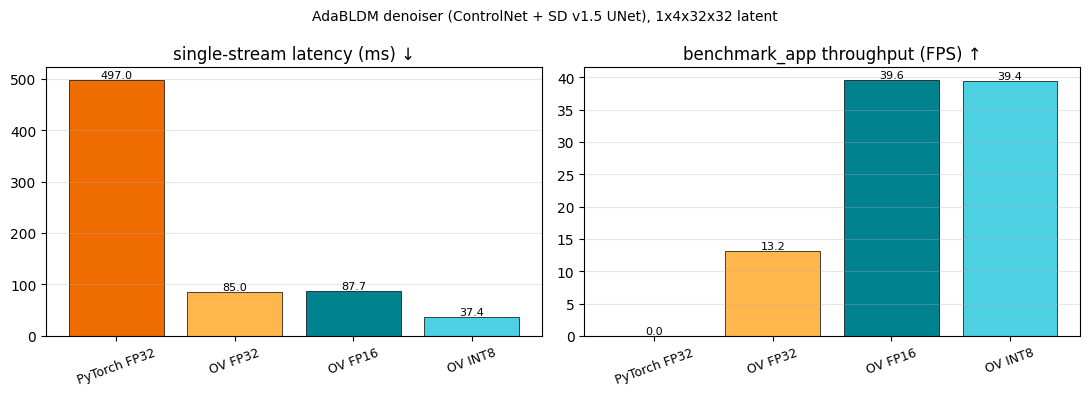

In [17]:
import matplotlib.pyplot as plt
panels = [("sync_latency_ms", "single-stream latency (ms) ↓"), ("bench_fps", "benchmark_app throughput (FPS) ↑")]
lbl = [r["config"].replace("OpenVINO", "OV").replace(" (NNCF)", "").replace(" (CPU)", "") for r in table]
col = ["#ef6c00", "#ffb74d", "#00838f", "#4dd0e1"][: len(table)]
fig, axs = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4))
for ax, (key, title) in zip(axs, panels):
    vals = [r[key] or 0 for r in table]
    b = ax.bar(lbl, vals, color=col, edgecolor="k", lw=0.5); ax.bar_label(b, fmt="%.1f", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=20, labelsize=9); ax.grid(axis="y", alpha=0.3)
fig.suptitle("AdaBLDM denoiser (ControlNet + SD v1.5 UNet), 1x4x32x32 latent", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "images/ov_vs_pytorch.png", dpi=130); plt.show()